# Test Notebook for Optical Flow

In [1]:
import cv2
import numpy as np 
import matplotlib.pyplot as plt
import os

In [2]:
# img_s1_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/sonar_samples/s185c832.jpg"
# img_s2_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/sonar_samples/s189c840.jpg"

img_s1_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/1770383784_427638908.png"
img_s2_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/1770383784_827672635.png"

img_s1 = cv2.imread(img_s1_path, cv2.IMREAD_GRAYSCALE)
img_s2 = cv2.imread(img_s2_path, cv2.IMREAD_GRAYSCALE)

Text(0.5, 1.0, 'Frame S2')

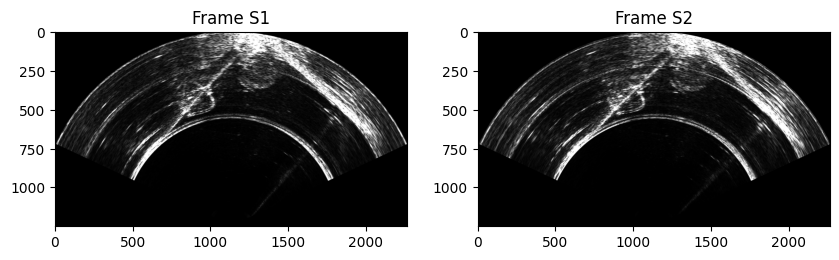

In [3]:
plt.figure(figsize=(10,10))

plt.subplot(1, 2, 1)
plt.imshow(img_s1, cmap='gray')
plt.title("Frame S1")

plt.subplot(1, 2, 2)
plt.imshow(img_s2, cmap='gray')
plt.title("Frame S2")

In [4]:

flow = cv2.calcOpticalFlowFarneback(
    img_s1, img_s2, 
    None,
    pyr_scale=0.5,      # Pyramid scale
    levels=3,            # Number of pyramid layers
    winsize=10,          # Averaging window size
    iterations=3,        # Number of iterations at each pyramid level
    poly_n=5,            # Size of pixel neighborhood
    poly_sigma=1.2,      # Standard deviation for Gaussian
    flags=0
)

print("Image size (h,w): ", img_s1.shape)
print("Optical Flow size: ", flow.shape)

Image size (h,w):  (1250, 2266)
Optical Flow size:  (1250, 2266, 2)


In [5]:
magnitude = np.sqrt(flow[:,:,0]**2 + flow[:,:,1]**2)
mask = magnitude <= 5
flow[mask] = 0  # zero out low-magnitude vectors in place

In [6]:
flow.shape

(1250, 2266, 2)

In [7]:
flow_img = cv2.cvtColor(img_s2, cv2.COLOR_GRAY2BGR)

In [8]:
step = 20

# Draw arrows for the flow vectors
h, w = img_s2.shape
y, x = np.mgrid[step//2:h:step, step//2:w:step].reshape(2, -1).astype(int)

for i in range(len(x)):
    xi, yi = x[i], y[i]
    # Get flow at this point
    dx, dy = flow[yi, xi]
    
    # Only draw if motion is significant (threshold to reduce clutter)
    magnitude = np.sqrt(dx**2 + dy**2)
    if magnitude > 5:  # Adjust threshold as needed
        # Calculate end point of arrow
        x_end = int(xi + dx)
        y_end = int(yi + dy)
        
        # Draw blue arrow
        cv2.arrowedLine(flow_img, (xi, yi), (x_end, y_end), 
                        (0, 255, 0),  # Blue color (BGR format)
                        thickness=2, 
                        tipLength=0.3)


Text(0.5, 1.0, 'Flow')

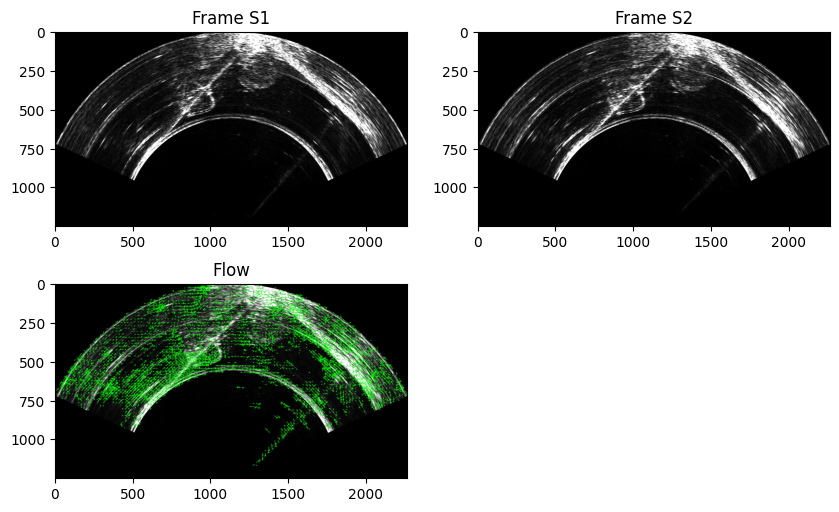

In [9]:
flow_img_rgb = cv2.cvtColor(flow_img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,6))

plt.subplot(2, 2, 1)
plt.imshow(img_s1, cmap='gray')
plt.title("Frame S1")

plt.subplot(2, 2, 2)
plt.imshow(img_s2, cmap='gray')
plt.title("Frame S2")

plt.subplot(2, 2, 3)
plt.imshow(flow_img_rgb)
plt.title("Flow")

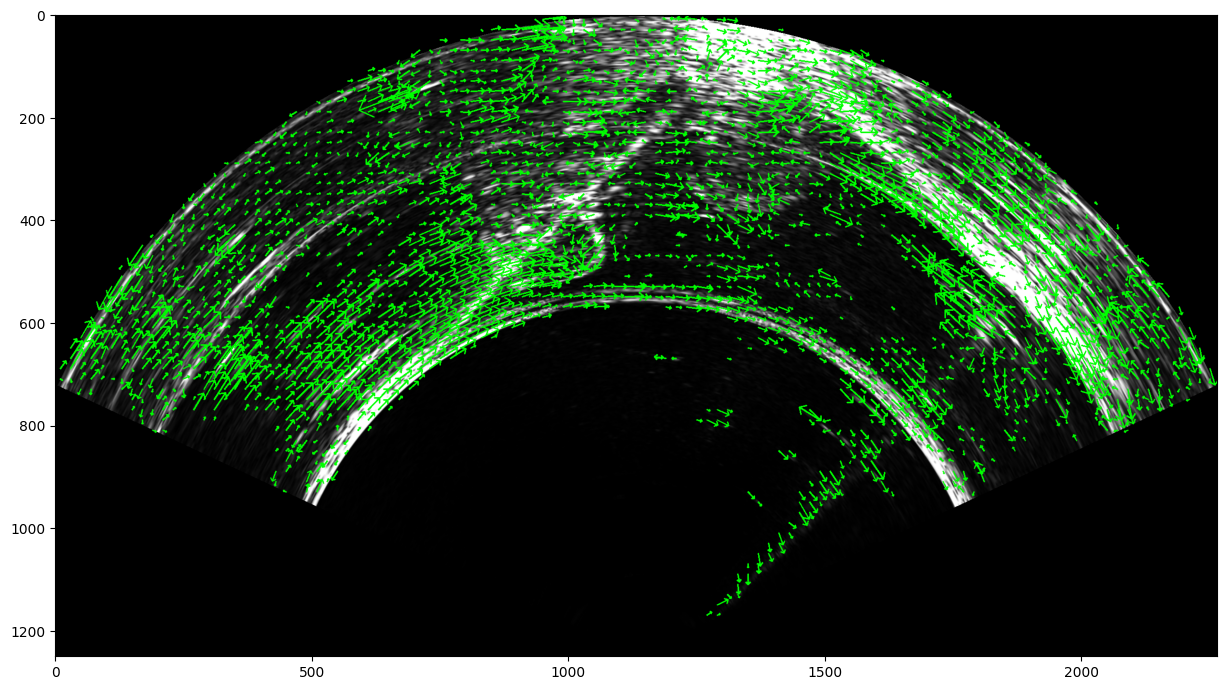

In [10]:
plt.figure(figsize=(15,20))
plt.imshow(flow_img_rgb)

In [90]:
class SonarOpticalFlowRansacPose: 

    def __init__(self, debug=False, max_range=5, max_aperture_deg=130, height=100, width=100, min_magnitude=10, n_points=10, threshold=100, max_iter=50):
        # logging debugging info 
        self.debug = debug

        # current sonar configuration (maximum range and aperture)
        # while the range is configurable (0.1m-30m), 
        # the aperture is fixed between high frequency mode (40 deg) and low frequency 130 deg)
        self.max_range = max_range                       
        self.max_aperture_deg = max_aperture_deg

        # sonar image dimensions
        self.height = height
        self.width = width
        # minimal flow magnitude to be considered
        self.min_magnitude = min_magnitude

        # resolution on the sonar x axis [m/pixels] (origin-to-forward)
        self.resolution_x = self.max_range/self.height              
        # resolution on the sonar y axis [m/pixels] (origin-to-right)
        self.max_aperture_rad = self.max_aperture_deg * np.pi / 180
        self.resolution_y = (self.max_range*np.sin(self.max_aperture_rad/2))/self.width    

        # Initialize optical flow matrix in the image coordinates
        self.cv_flow = np.zeros(shape=(self.height, self.width, 2))  # (y,x,flow) optical flow matrix, OpenCV convention
        
        # Fixed transformation from Im frame to Sonar frame (S_p = S_T_Im * Im_p)
        # Im frame (opencv convention): top left corner of the image, y downward, x right-oriented
        # to Sonar frame (centered in the sonar = middle bottom): x upward, y right-oriented 
        self.S_R_Im = np.array([[0, -1], [1, 0]])              # Rotation    from Im (OpenCV) to Sonar
        self.S_t_Im = np.array([self.height, -self.width//2])  # Translation from Im (OpenCV) to Sonar 
        self.S_T_Im = np.vstack([
            np.column_stack([self.S_R_Im, self.S_t_Im]),
            [0, 0, 1]
        ])

        # parameters for Ransac Estimation
        # best model unkowns (translation in x, y and rotation)
        self.tx_best = 0
        self.ty_best = 0
        self.dtheta_best = 0

        self.inliers_best = None

        # number of points used for estimation 
        self.n_points = n_points 
        # list of inliers [[x1,y1], [x2, y2], ..]
        self.inliers = np.zeros(shape=(n_points, 2))
        # inliers-outliers threshold 
        self.threshold = threshold
        # max RANSAC iteration 
        self.max_iter = max_iter

        if self.debug:
            print(f'''SonarOpticalFlowRansacPose initialized:
                        range_max={self.max_range:.2f} m  
                        aperture_max={self.max_aperture_deg:.2f} deg
                        x_res={self.resolution_x:.4f} m/pixels
                        y_res={self.resolution_y:.4f} m/pixels''')


    def update_resolution(self):
        # resolution on the sonar x axis [m/pixels] (origin-to-forward)
        self.resolution_x = self.max_range/self.height              
        # resolution on the sonar y axis [m/pixels] (origin-to-right)
        self.max_aperture_rad = self.max_aperture_deg * np.pi / 180
        self.resolution_y = (self.max_range*np.sin(self.max_aperture_rad/2))/self.width    

    # In case the sonar image frame size changes (e.g. different range or aperture - freq mode)
    def set_image_shape(self, frame):
        self.height = frame.shape[0]
        self.width = frame.shape[1]
        self.update_resolution()
        if self.debug:
            print(f'''SonarOpticalFlowRansacPose Updated:
                        range_max={self.max_range:.2f} m  
                        aperture_max={self.max_aperture_deg:.2f} deg
                        x_res={self.resolution_x:.4f} m/pixels
                        y_res={self.resolution_y:.4f} m/pixels''')

    # In case the sonar configuration changes (e.g. different range or aperture - freq mode)
    def set_sonar_config(self, new_max_range, new_max_aperture):
        self.max_range = new_max_range                       
        self.max_aperture_deg = new_max_aperture

        self.update_resolution()
        if self.debug:
            print(f'''SonarOpticalFlowRansacPose Updated:
                        range_max={self.max_range:.2f} m  
                        aperture_max={self.max_aperture_deg:.2f} deg
                        x_res={self.resolution_x:.4f} m/pixels
                        y_res={self.resolution_y:.4f} m/pixels''')

    def compute_image_flow(self, s1_frame, s2_frame, min_flow_magnitude=0.5):

        self.cv_flow = cv2.calcOpticalFlowFarneback(
            s1_frame, 
            s2_frame, 
            None,
            pyr_scale=0.5,      # Pyramid scale
            levels=3,            # Number of pyramid layers
            winsize=10,          # Averaging window size
            iterations=3,        # Number of iterations at each pyramid level
            poly_n=5,            # Size of pixel neighborhood
            poly_sigma=1.2,      # Standard deviation for Gaussian
            flags=0
        )

        magnitude = np.sqrt(self.cv_flow[:,:,0]**2 + self.cv_flow[:,:,1]**2)
        mask = magnitude <= min_flow_magnitude
        self.cv_flow[mask] = 0  # zero out low-magnitude vectors in place

        return self.cv_flow

    # def apply_flow_sonar(self, p_s1):
    #     p_s2_flow = np.zeros(shape=p_s1.shape)

    #     flow_vec = self.cv_flow.reshape(-1, 2).T           # (2, h*w)
    #     flow_rotated = self.R_S_Im @ flow_vec              # (2, h*w)
    #     flow_rotated = flow_rotated.T.reshape(self.height, self.width, 2)  # (h, w, 2)

    #     p_s2_flow[:,:,0] = p_s1[:,:,0] + self.resolution * flow_rotated[:,:,0]
    #     p_s2_flow[:,:,1] = p_s1[:,:,1] + self.resolution * flow_rotated[:,:,1]

    #     return p_s2_flow
    
    def apply_cv_flow(self, p_s1):
        y = p_s1[:, 0].astype(int)
        x = p_s1[:, 1].astype(int)

        flow = self.cv_flow[y, x]        # shape (N, 2)

        p_s2_flow = p_s1 + flow          # shape (N, 2)

        return p_s2_flow
    
    def compute_transform(self, dx, dy, dth):
        return np.linalg.inv(np.array([[np.cos(dth), -np.sin(dth), dx], [np.sin(dth), np.cos(dth), dy], [0, 0, 1]]))
  
    def compute_equation_matrix(self, p_s1, p_s2):
    

        alpha = p_s2[:,1] / p_s2[:,0]
        beta  = p_s2[:,0] + np.square(p_s2[:,1])/p_s2[:,0]
        gamma = p_s1[:,1] - p_s2[:,1]/p_s2[:,0] * p_s1[:,0]

        A = np.array([[-alpha[i], 1, beta[i]] for i in range(len(alpha))])
        b = np.array(gamma)

        return A, b

    def solve_pose(self, A : np.ndarray , b: np.ndarray):
        if A.shape[0] ==3 and A.shape[1] ==3: # inversion 
            x = np.linalg.inv(A) @ b
            x[2] = np.arcsin(x[2])
            return x
        else: # least squares (pseudo-inverse)
            x = np.linalg.inv(A.T @ A) @ A.T @ b
            x[2] = np.arcsin(x[2])
            return x
    
    def measure_consensus(self, p_s1, T_s1_s2_estim):

        p_s1_tilde = np.hstack([p_s1, np.ones((len(p_s1), 1))])  # (10, 3)
        p_s2_tilde = (T_s1_s2_estim @ p_s1_tilde.T).T                  # (10, 3)
        p_s2_estim = p_s2_tilde[:, :2]    
                                      # (10, 2)
        estim_flow = np.zeros_like(self.cv_flow)
        estim_flow[p_s1[:,0], p_s1[:,1],:] = p_s2_estim - p_s1

        for p in p_s1:
            error = np.sqrt((self.cv_flow[p[0],p[1],0] - estim_flow[p[0],p[1],0])**2 + (self.cv_flow[p[0], p[1],1] - estim_flow[p[0],p[1],1])**2)
            if error < self.threshold: 
                self.inliers = np.append(self.inliers, [[p[0], p[1]]], axis=0)
                
        return self.inliers
    

    def estimate_2d_flow_motion(self, s1_frame, s2_frame):

        self.compute_image_flow(s1_frame, s2_frame, min_flow_magnitude = self.min_magnitude)
        
        # Get indices where flow is higher than min magnitude 
        nonzero_y, nonzero_x = np.where(
            np.sqrt(self.cv_flow[:,:,0]**2 + self.cv_flow[:,:,1]**2) > self.min_magnitude
        )
        nonzero_coords = np.column_stack((nonzero_y, nonzero_x))

        # Remove points where x == 0 or y == 0
        valid_mask = (nonzero_coords[:, 0] != 0) & (nonzero_coords[:, 1] != 0)
        nonzero_coords = nonzero_coords[valid_mask]

        n_iter = 0
        n_best_inliers = self.n_points
        while n_iter < self.max_iter:
            if self.debug:
                print("START ITERATION ", n_iter)

            if self.inliers_best is None: 
                self.inliers_best = self.inliers

            # re-initialize inlier set
            self.inliers = np.zeros(shape=(self.n_points, 2))

            sampled_idx = np.random.choice(len(nonzero_coords), size=self.n_points, replace=False)
            self.inliers = nonzero_coords[sampled_idx]  # (n_points, 2) of [y, x]
            
            # s1_frame_bgr = cv2.cvtColor(s1_frame, cv2.COLOR_GRAY2BGR)
            # for p in self.inliers:
            #     cv2.circle(s1_frame_bgr, (p[1],p[0]), 5,
            #             color=(0,0,255),
            #             thickness=-1)
            # text = f"Iteration: {n_iter}"
            # cv2.putText(s1_frame_bgr, text, (50, self.height - 20), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2, cv2.LINE_AA)
            # for i in range(len(self.inliers)):
            #     xi, yi = self.inliers[i,1], self.inliers[i,0]
            #     # Get flow at this point
            #     dx, dy = self.cv_flow[yi, xi]
            #     x_end = int(xi + dx)
            #     y_end = int(yi + dy)
                
            #     # Draw blue arrow
            #     cv2.arrowedLine(s1_frame_bgr, (xi, yi), (x_end, y_end), 
            #                     (0, 255, 0),  # Green color (BGR format)
            #                     thickness=2, 
            #                     tipLength=0.3)

        
            # cv2.imshow("Selected Points", s1_frame_bgr)
            # print("Press Space to Continue")
            # key = cv2.waitKey(0)  # waits indefinitely for a key press

            # if key == 32:  # Space
            #     print("Start Solving Pose")
            # elif key == 27:  # Esc
            #     print("Aborted")
            #     break
                
            p_s2 = self.apply_cv_flow(self.inliers)
            A, b = self.compute_equation_matrix(self.inliers, p_s2)
            x = self.solve_pose(A, b)
            x[1] = x[1] * self.resolution_y
            x[0] = x[0] * self.resolution_x 
            if self.debug:
                print(f"Estimate: tx=", x[0], "m | ty=", x[1], " m | theta=", x[2], " rad")

            T_s1_s2_estim = self.compute_transform(x[0], x[1], x[2])
            self.inliers = self.measure_consensus(nonzero_coords, T_s1_s2_estim)
            n_inliers = len(self.inliers)
            if self.debug:
                print("Inliers Number: ", n_inliers)
            if n_inliers > n_best_inliers: 
                self.tx_best = x[0]
                self.ty_best = x[1]
                self.dtheta_best = x[2]
                if self.debug:
                    print("Update optimal model")

                self.inliers_best = self.inliers
                n_best_inliers = n_inliers
            if self.debug:
                print(f" \n--------------------------------------\n ")
            n_iter += 1
        if self.debug:
            print(f"\nUsing all ({n_best_inliers}) best inliers over best model")
        p_s2_optim = self.apply_cv_flow(self.inliers_best)
        A_optim,b_optim = self.compute_equation_matrix(self.inliers_best, p_s2_optim)
        x_optim = self.solve_pose(A_optim, b_optim)

        cv2.destroyAllWindows()
        x_optim[1] = x_optim[1] * self.resolution_y
        x_optim[0] = x_optim[0] * self.resolution_x 
        if self.debug:
            print("Optimal Estimate: tx=", x_optim[0], "m | ty=", x_optim[1], " m | theta=", x_optim[2], " rad")
        
        return x_optim


In [91]:
img_s1_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/1770383784_427638908.png"
img_s2_path = "/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/1770383784_827672635.png"

img_s1 = cv2.imread(img_s1_path, cv2.IMREAD_GRAYSCALE)
img_s2 = cv2.imread(img_s2_path, cv2.IMREAD_GRAYSCALE)

scale_factor = 0.6
img_s1 = cv2.resize(img_s1, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_LINEAR)
img_s2 = cv2.resize(img_s2, None, fx=scale_factor, fy=scale_factor, interpolation=cv2.INTER_LINEAR)

In [92]:
flow_pose = SonarOpticalFlowRansacPose(max_range=5, max_aperture_deg=130, 
                                       height=img_s1.shape[0], width=img_s1.shape[1], 
                                       min_magnitude=5, 
                                       n_points=25, threshold=5, max_iter=10)


In [93]:
x_optim = flow_pose.estimate_2d_flow_motion(img_s1, img_s2)

In [94]:
def draw_axes(T, frame):
    x = np.array([1, 0, 1])
    y = np.array([0, 1, 1])

    Origin = np.array([0, 0, 1])
    
    Origin_new = T @ Origin.T
    x_new = T @ x.T - Origin_new
    y_new = T @ y.T - Origin_new
    plt.text(Origin_new[0]-0.5, Origin_new[1]-0.5, frame)
    plt.quiver(Origin_new[0], Origin_new[1], x_new[0], x_new[1], scale=10, color='red')
    plt.quiver(Origin_new[0], Origin_new[1], y_new[0], y_new[1], scale=10, color='green')
    plt.scatter(Origin_new[0], Origin_new[1], c='black')

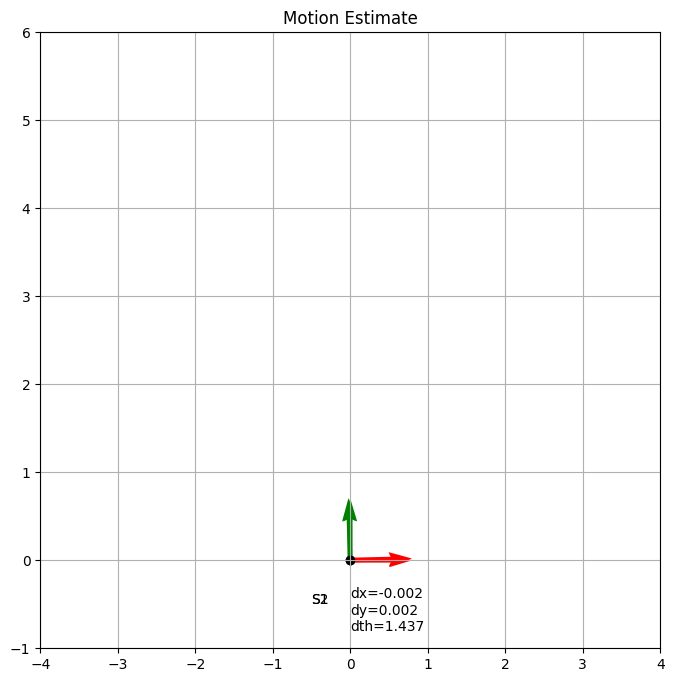

In [95]:
T_sonar_img = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]])

T_s1_s2_estim = np.linalg.inv(flow_pose.compute_transform(x_optim[0], x_optim[1], x_optim[2]))

plt.figure(figsize=(8,8))
plt.title("Motion Estimate")
plt.xlim(-4,4)
plt.ylim(-1,6)
# plt.autoscale(enable=True, axis='both', tight=True)
draw_axes(np.eye(3), 'S1')
draw_axes(T_s1_s2_estim, 'S2')

dth_deg = x_optim[2] * 180 / np.pi
s = f"dx={x_optim[0]:.3f}\ndy={x_optim[1]:.3f}\ndth={dth_deg:.3f}"
plt.text(0, -0.8, s)

plt.grid()

plt.show()


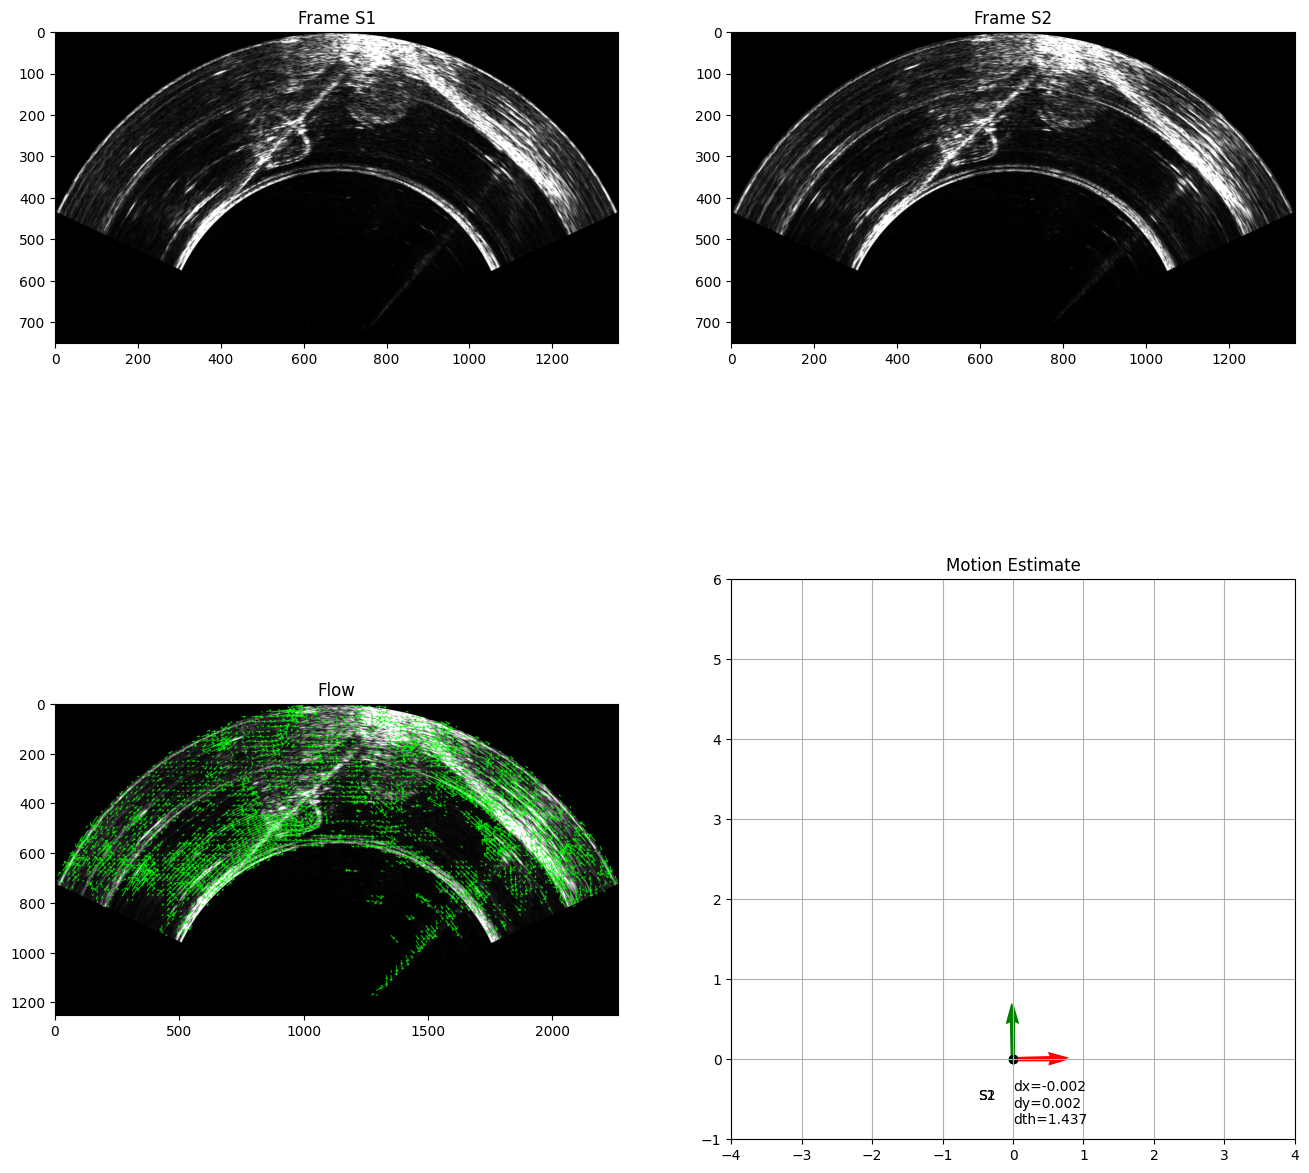

In [96]:

plt.figure(figsize=(16,16))

plt.subplot(2, 2, 1)
plt.imshow(img_s1, cmap='gray')
plt.title("Frame S1")

plt.subplot(2, 2, 2)
plt.imshow(img_s2, cmap='gray')
plt.title("Frame S2")

plt.subplot(2, 2, 3)
plt.imshow(flow_img_rgb)
plt.title("Flow")

plt.subplot(2,2,4)
plt.title("Motion Estimate")
plt.xlim(-4,4)
plt.ylim(-1,6)
# plt.autoscale(enable=True, axis='both', tight=True)
draw_axes(np.eye(3), 'S1')
draw_axes(T_s1_s2_estim, 'S2')

dth_deg = x_optim[2] * 180 / np.pi
s = f"dx={x_optim[0]:.3f}\ndy={x_optim[1]:.3f}\ndth={dth_deg:.3f}"
plt.text(0, -0.8, s)

plt.grid()

plt.show()

dx=-0.044
dy=0.024
dth=-0.213


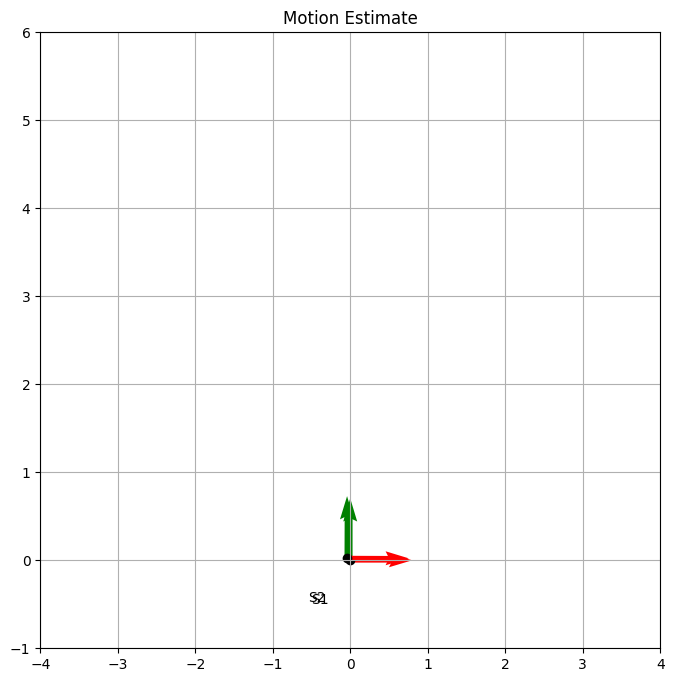

dx=-0.027
dy=0.024
dth=-0.138


In [ ]:
# Iteratively estimate motion and trajectory 
scale_factor = 0.6

flow_pose = SonarOpticalFlowRansacPose(max_range=5, max_aperture_deg=130, 
                                       height=img_s1.shape[0], width=img_s1.shape[1], 
                                       min_magnitude=5, 
                                       n_points=25, threshold=5, max_iter=10)

import os 

imgs_path = '/home/ale/sonar_ws/src/oculus-ros2-cpp-driver/OCULUS_ROS2/Data/images/sonar/2026_02_06_14_15/cartesian/'
image_files = sorted([
    f for f in os.listdir(imgs_path)
    if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tiff'))
])

plt.figure(figsize=(8,8))
plt.title("Motion Estimate")
plt.xlim(-4,4)
plt.ylim(-1,6)
plt.grid()
plt.ion()  # Enable interactive mode

T_t1 = np.eye(3)
draw_axes(T_t1, 'S1')

for i in range(len(image_files) - 1):
    img_s1 = cv2.imread(os.path.join(imgs_path, image_files[i]),   cv2.IMREAD_GRAYSCALE)
    img_s2 = cv2.imread(os.path.join(imgs_path, image_files[i+1]), cv2.IMREAD_GRAYSCALE)

    x_optim = flow_pose.estimate_2d_flow_motion(img_s1, img_s2)

    T_s1_s2_estim = np.linalg.inv(flow_pose.compute_transform(x_optim[0], x_optim[1], x_optim[2]))
    T_t2 = np.dot(T_t1, T_s1_s2_estim)

    # plt.autoscale(enable=True, axis='both', tight=True)

    draw_axes(T_t2, f'S{i+2}')

    dth_deg = x_optim[2] * 180 / np.pi
    print(f"dx={x_optim[0]:.3f}\ndy={x_optim[1]:.3f}\ndth={dth_deg:.3f}")

    #plt.text(0, -0.8, s)
    plt.draw()
    plt.pause(0.01)  # Small pause to render the update

    T_t1 = T_t2

plt.ioff()  # Disable interactive mode when done
plt.show()  # Keep the final plot open
